# Audio2Tool paper preparation

Regenerate figures and tables from saved measurements. This notebook performs no training, downloads or model inference. `PAPER.tex` is kept unchanged; consult the claim register and discrepancies before incorporating these assets. All experiments use one training seed.

In [1]:
from pathlib import Path
import os, sys, csv, html
ROOT = Path.cwd() if (Path.cwd() / 'PAPER.tex').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
from nano_learning.reporting import build, DEST
from IPython.display import display, Markdown, Image, HTML
result = build()
def show_table(name, columns):
    records = list(csv.DictReader((DEST / 'tables' / (name + '.csv')).open()))
    display(HTML('<table><tr>' + ''.join('<th>'+html.escape(k)+'</th>' for k in columns) + '</tr>' + ''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in columns)+'</tr>' for r in records) + '</table>'))
def figure(name):
    display(Image(filename=str(DEST / 'figures' / (name + '.png'))))
print('Exports:', DEST)


Exports: /home/aaron/sc4001_project/paper/generated


## Dataset

Counts distinguish recording entries, requests, source components and distinct audio files. Duration sums recording references (matching historical reporting); unique-file duration is exported separately. The filtered benchmark is a restricted cohort and is not speaker-disjoint.

In [2]:
show_table('dataset', ['tier','scope','entries','requests','audio_files','hours'])
show_table('splits', ['split','components','entries','requests','audio_files','hours'])
print(result['panel'])

tier,scope,entries,requests,audio_files,hours
1,source,4292,2146,4292,2.6569724884259256
1,filtered,3849,1925,3849,2.241522013888889
2,source,6320,3160,6320,5.381399826388889
2,filtered,4208,2104,4208,3.403493402777778
3,source,4292,2146,4292,6.684397951388888
3,filtered,120,60,120,0.12920774305555555
4,source,4278,2132,4276,3.6827344675925926
4,filtered,2763,1380,2762,2.3084957060185185
5,source,4292,2146,4292,12.699389756944443
5,filtered,799,519,799,1.8884230902777777


split,components,entries,requests,audio_files,hours
train,2485,10287,5330,10614,10.256622037037037
validation,513,2141,1105,2205,2.116371886574074
test,509,2126,1096,2192,2.122213310185185


{'recording_entries': 40, 'distinct_requests': 40, 'source_components': 36, 'ids': ['t1:row4291', 't1:row4032', 't1:row2085', 't1:row3063', 't1:row3677', 't1:row3241', 't2:row6136', 't2:row6242', 't2:row4367', 't2:row109', 't2:row5748', 't2:row6004', 't3:row937', 't3:row2903', 't3:row3211', 't3:row3249', 't4:row4003', 't4:row4130', 't4:row2347', 't4:row2252', 't4:row3344', 't4:row3528', 't5:row4092', 't5:row4020', 't5:row555', 't5:row1926', 't5:row3241', 't5:row3358', 't6:row4148', 't6:row4199', 't6:row1995', 't6:row2519', 't6:row3530', 't6:row3802', 't7:row1985', 't7:row287', 't7:row462', 't7:row1874', 't7:row1901', 't8:row367'], 'label': 'mini-validation: training diagnostic', 'interpretation': 'Low-cost progress signal; not a full-split or deployment estimate.'}


## Warmups

Compare only the 640-update full-validation endpoints, with ties toward the smallest pool. Both models select 10%/640. Full validation occurs at 256, 512 and 640; mini-validation occurs at intervening 64-update boundaries. Rows show Samsone then Mellow; columns show response NLL (trailing 32-update mean), full-validation macro exact, and schema validity. Colors and line styles identify 10%, 30%, and 100% pools. Mellow ties at zero exact accuracy; 10% is selected by the tie-break. Metric definitions: `docs/metrics.md`.

model,pool,step,macro_exact,schema_validity,selected,historical_parent_step
samsone,0.1,640,0.12665806431514415,0.7113122171945702,True,640
samsone,0.3,640,0.12476648884983693,0.7407239819004525,False,640
samsone,1.0,640,0.12102446210364441,0.6882352941176471,False,640
mellow,0.1,640,0.0,0.7203619909502262,True,256
mellow,0.3,640,0.0,0.12805429864253393,False,256
mellow,1.0,640,0.0,0.6742081447963801,False,256


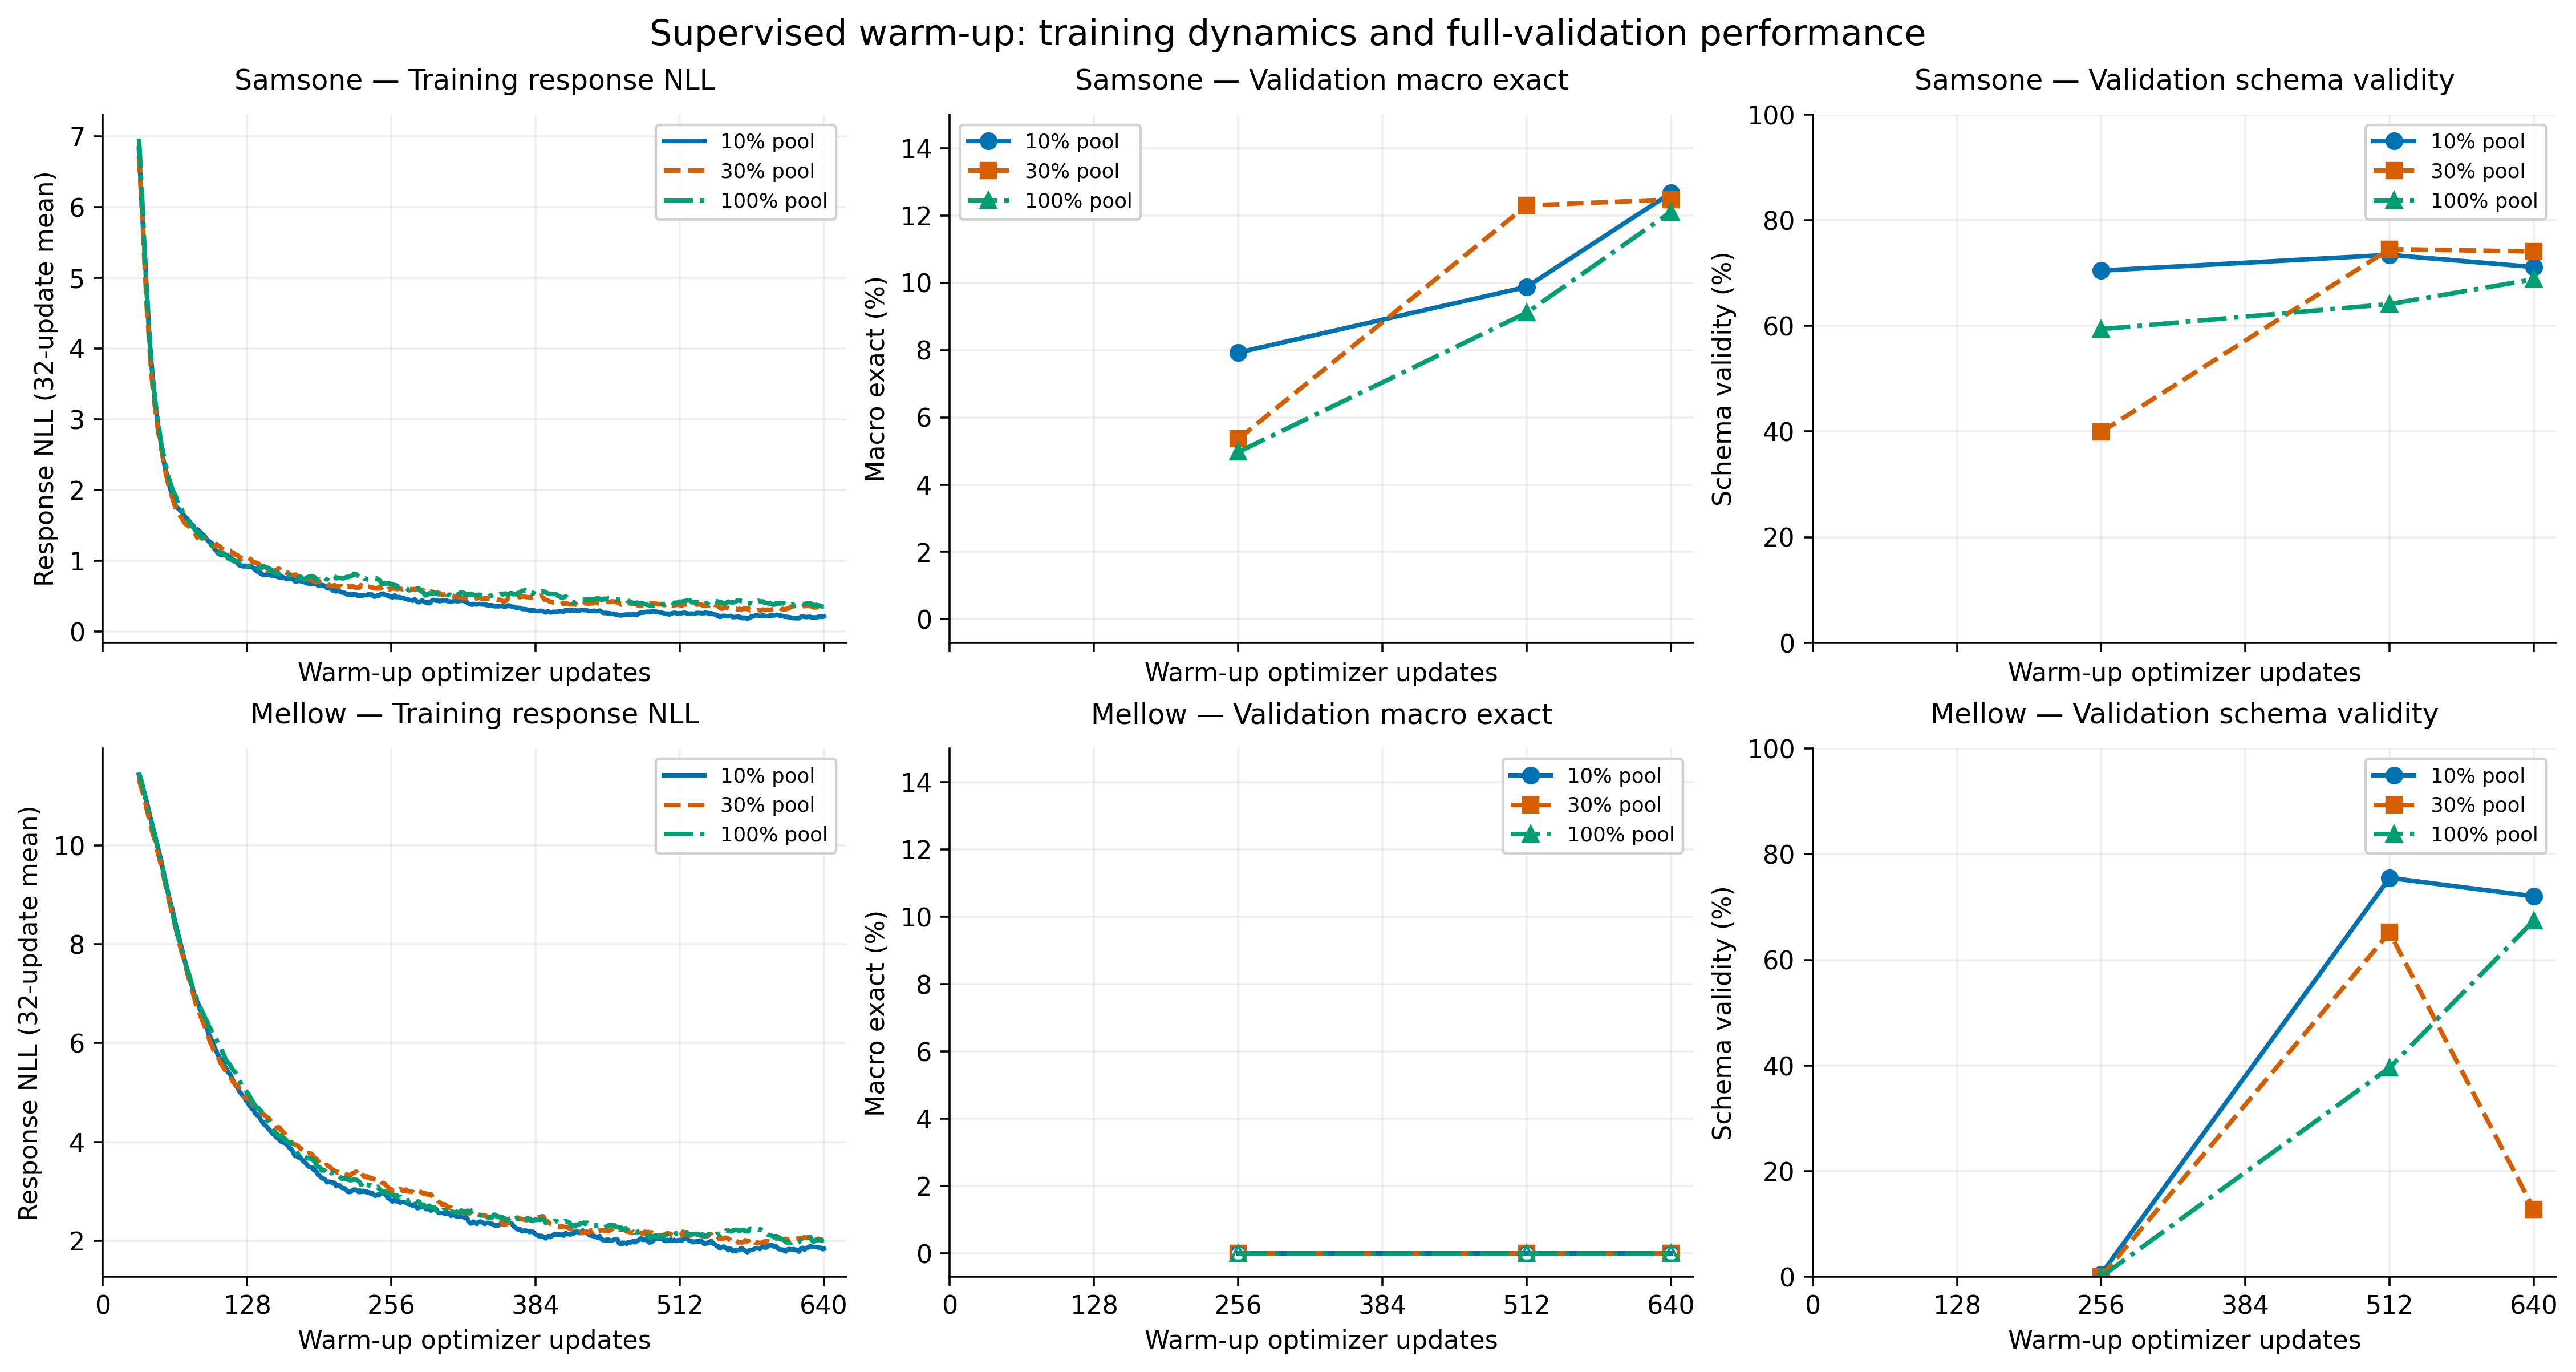

In [3]:
show_table('warmups', ['model','pool','step','macro_exact','schema_validity','selected','historical_parent_step'])
figure('warmups')

## +64 pilot

These are historical pilot **test** measurements. Samsone starts from 10%/640 (endpoint lineage 704). Mellow starts from **100%/256 (endpoint lineage 320)**. The corrected Mellow +64 configuration is disabled and unrun; its values cannot be inferred from these zeros or from the +1024 result.

model,arm,parent_pool,parent_updates,lineage_updates,macro_exact,binary,schema_validity
samsone,parent,0.1,640,640,0.08334720283137563,0.07162408759124088,0.7046076642335767
samsone,sft,0.1,640,704,0.09558440147937873,0.07983576642335767,0.708029197080292
samsone,binary,0.1,640,704,0.08600992745228901,0.07162408759124088,0.7176094890510949
samsone,typed,0.1,640,704,0.07572387414282282,0.06934306569343066,0.7223996350364964
mellow,parent,1.0,256,256,0.0,0.0,0.0
mellow,sft,1.0,256,320,0.0,0.0,0.0009124087591240876
mellow,binary,1.0,256,320,0.0,0.0,0.0
mellow,typed,1.0,256,320,0.0,0.0,0.0


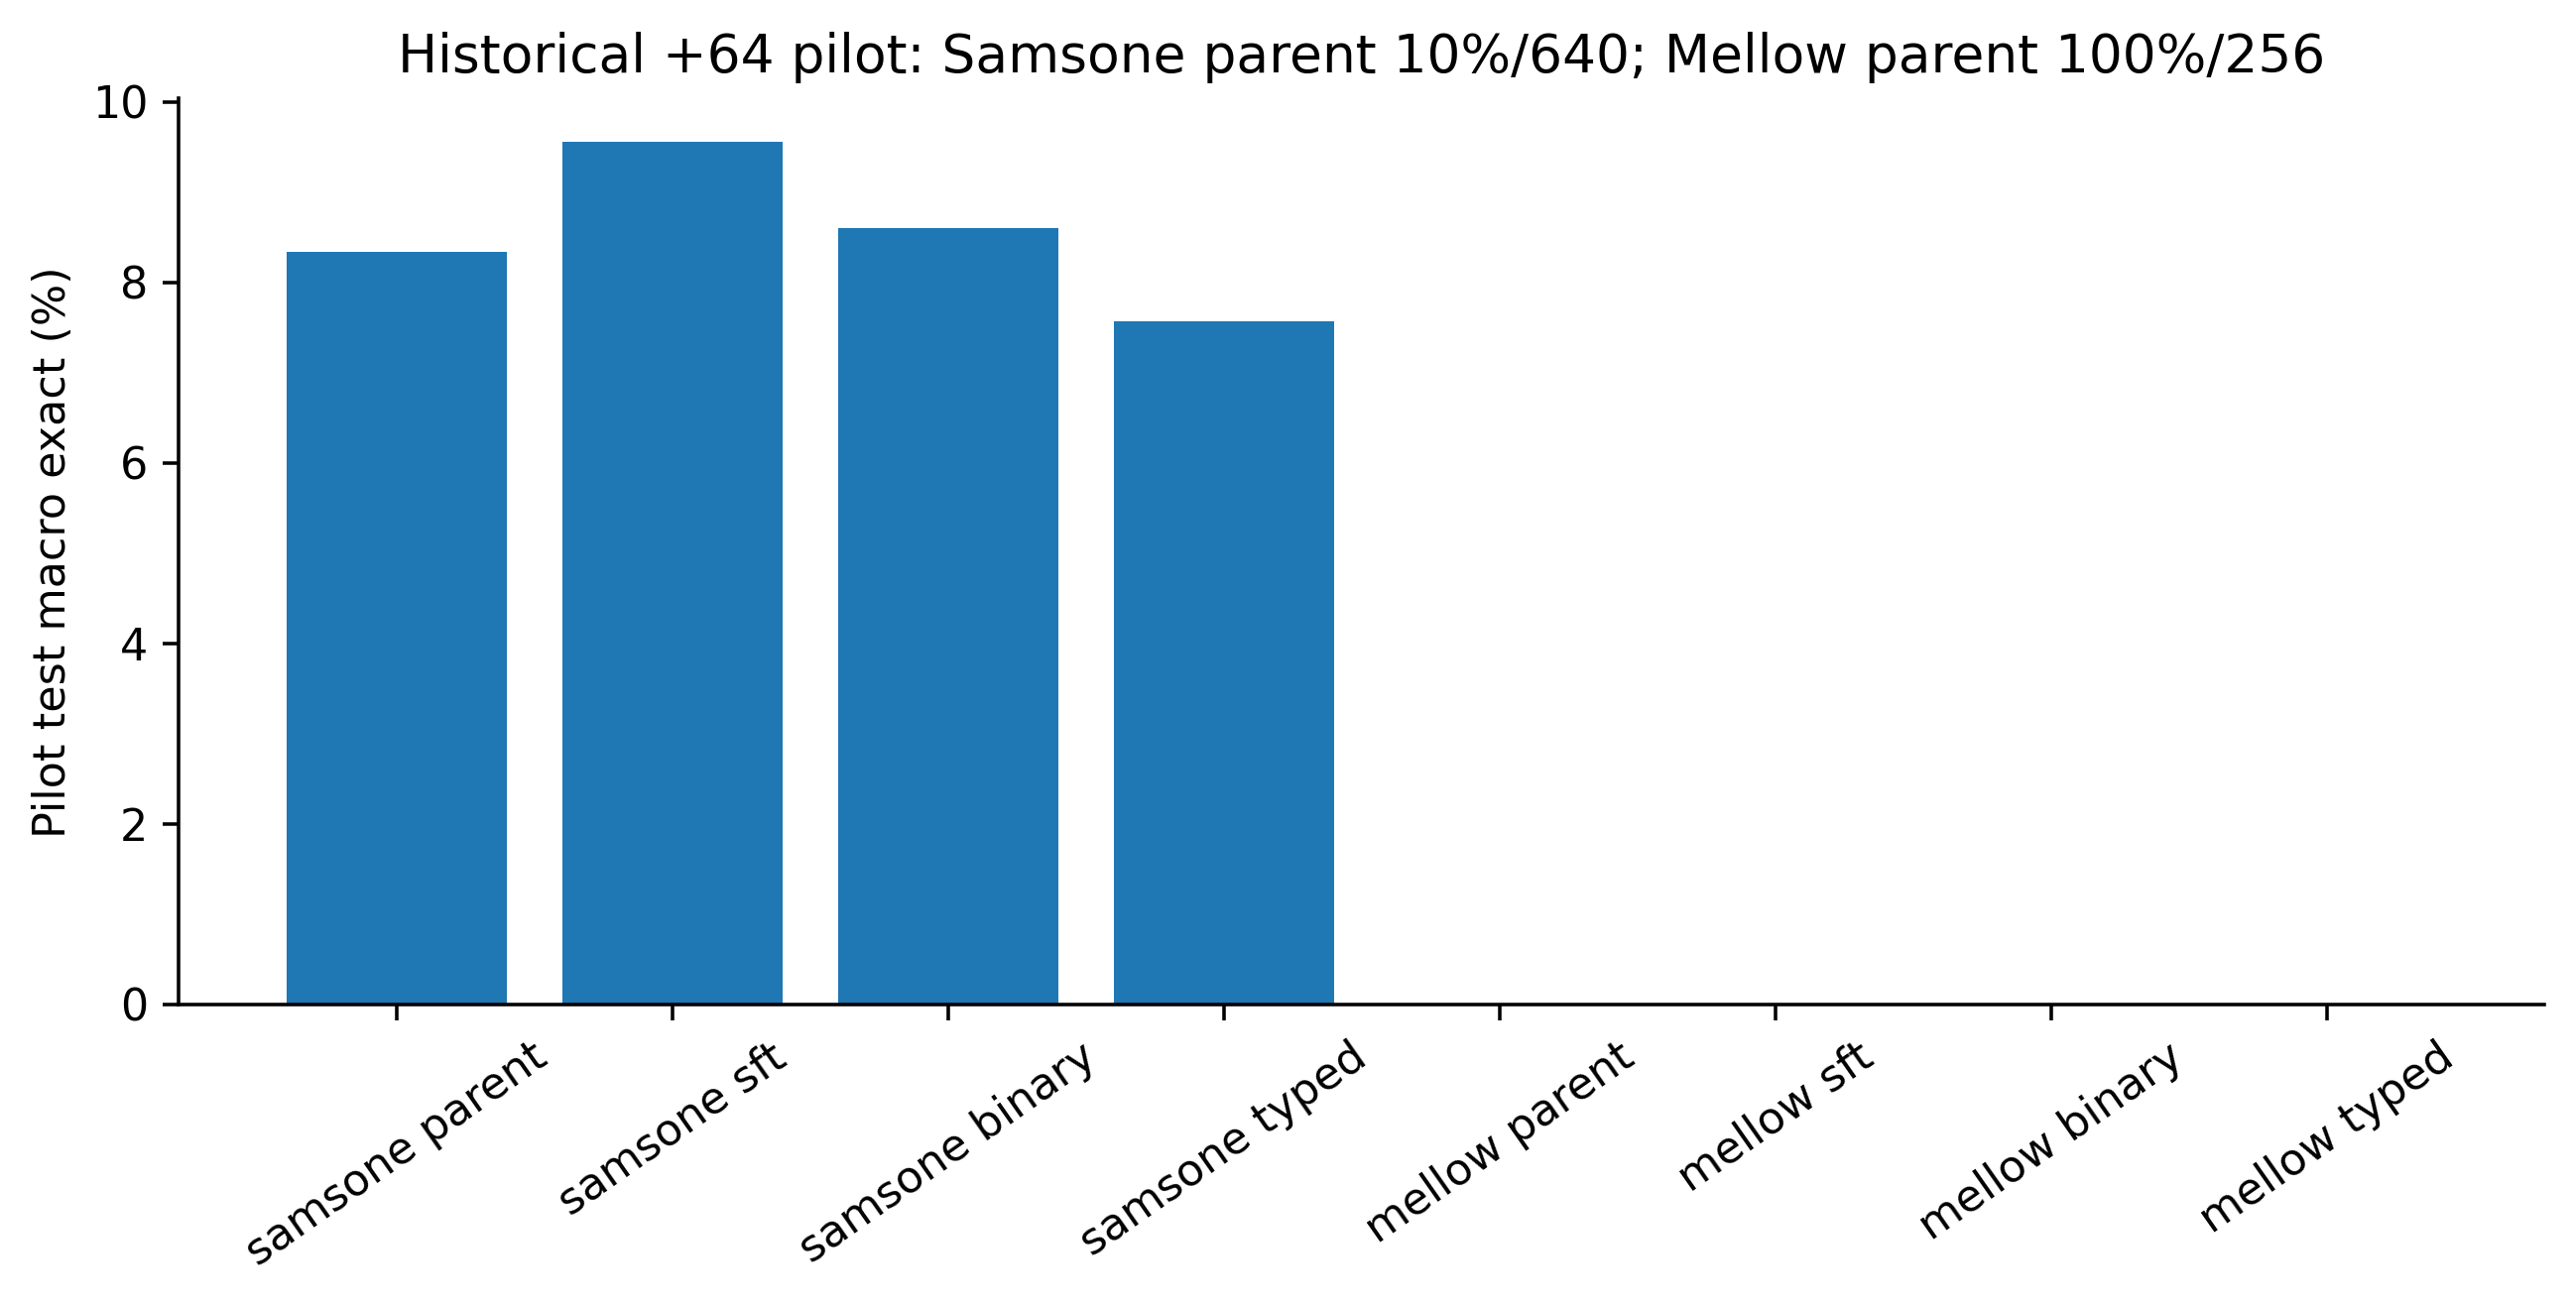

In [4]:
show_table('pilot_test', ['model','arm','parent_pool','parent_updates','lineage_updates','macro_exact','binary','schema_validity'])
figure('pilot64_test')

## +1024 comparison

Headline comparisons use full validation at the endpoint. Dashed trajectories are **mini-validation: training diagnostic**—40 recording entries, 40 distinct requests, 36 source components. They are not reliable estimates of full-split or deployment performance. Branches start independently from 10%/640; lineage is 1664. Mellow has SFT only. Training minutes sum optimizer-step timings and exclude loading, evaluation and checkpoint I/O.

model,arm,additional_updates,macro_exact,binary,argument_F1,schema_validity,training_minutes
samsone,sft,1024,0.22087667293752672,0.19592760180995475,0.2273421676362853,0.9090497737556561,11.628744432616319
samsone,binary,1024,0.14074489296743903,0.09502262443438914,0.11076384399913812,0.8493212669683258,113.34724552020003
samsone,typed,1024,0.12350729141365159,0.09276018099547512,0.11776449041154922,0.7348416289592761,118.40874693084842
mellow,sft,1024,0.0006459948320413437,0.00045248868778280545,0.00045248868778280545,0.6633484162895927,12.662176478345646
samsone,sft,4096,0.34604440571658274,0.34751131221719456,0.38599547511312216,0.983710407239819,44.176462486628836


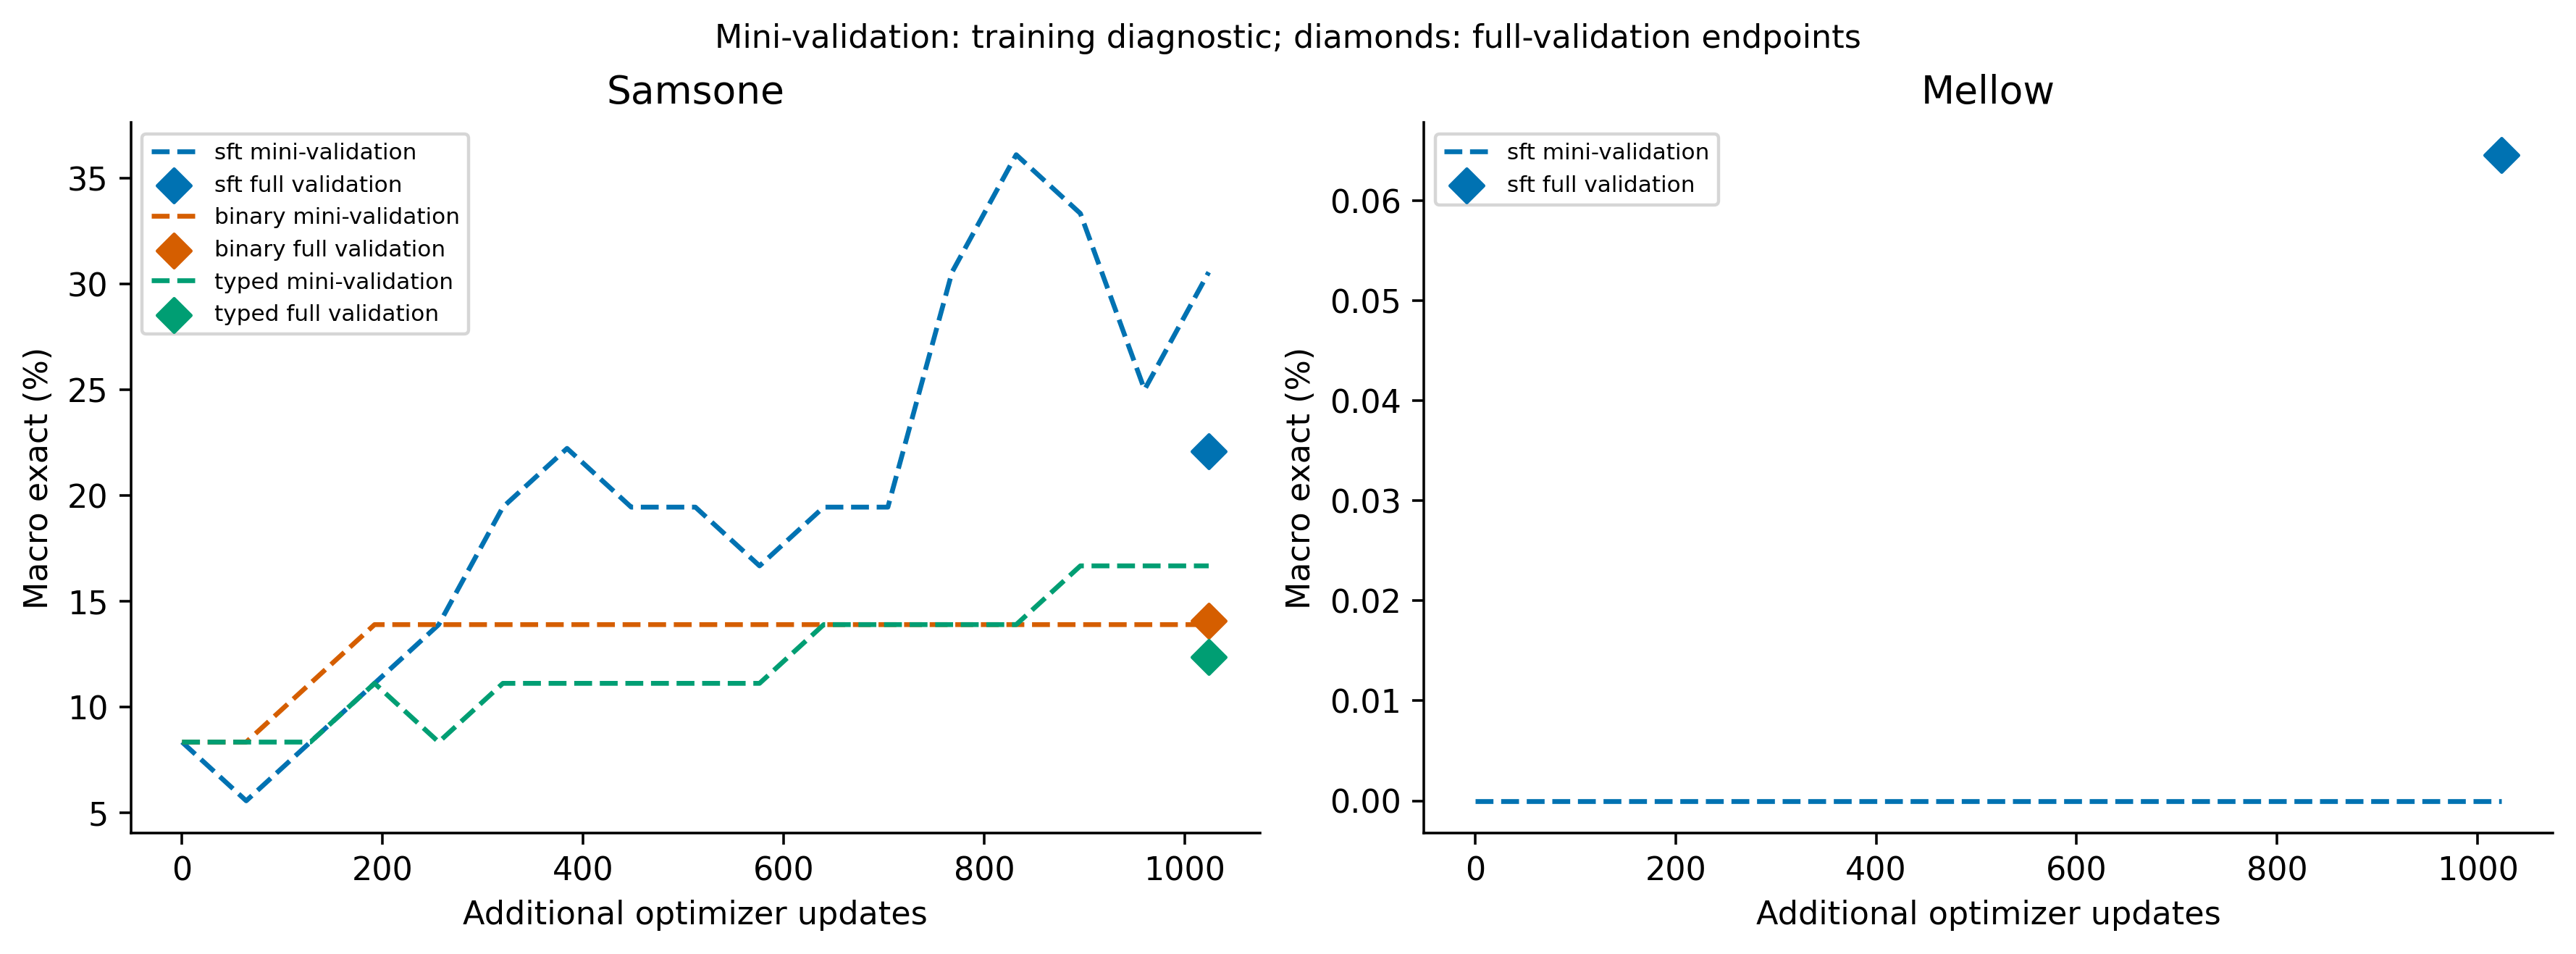

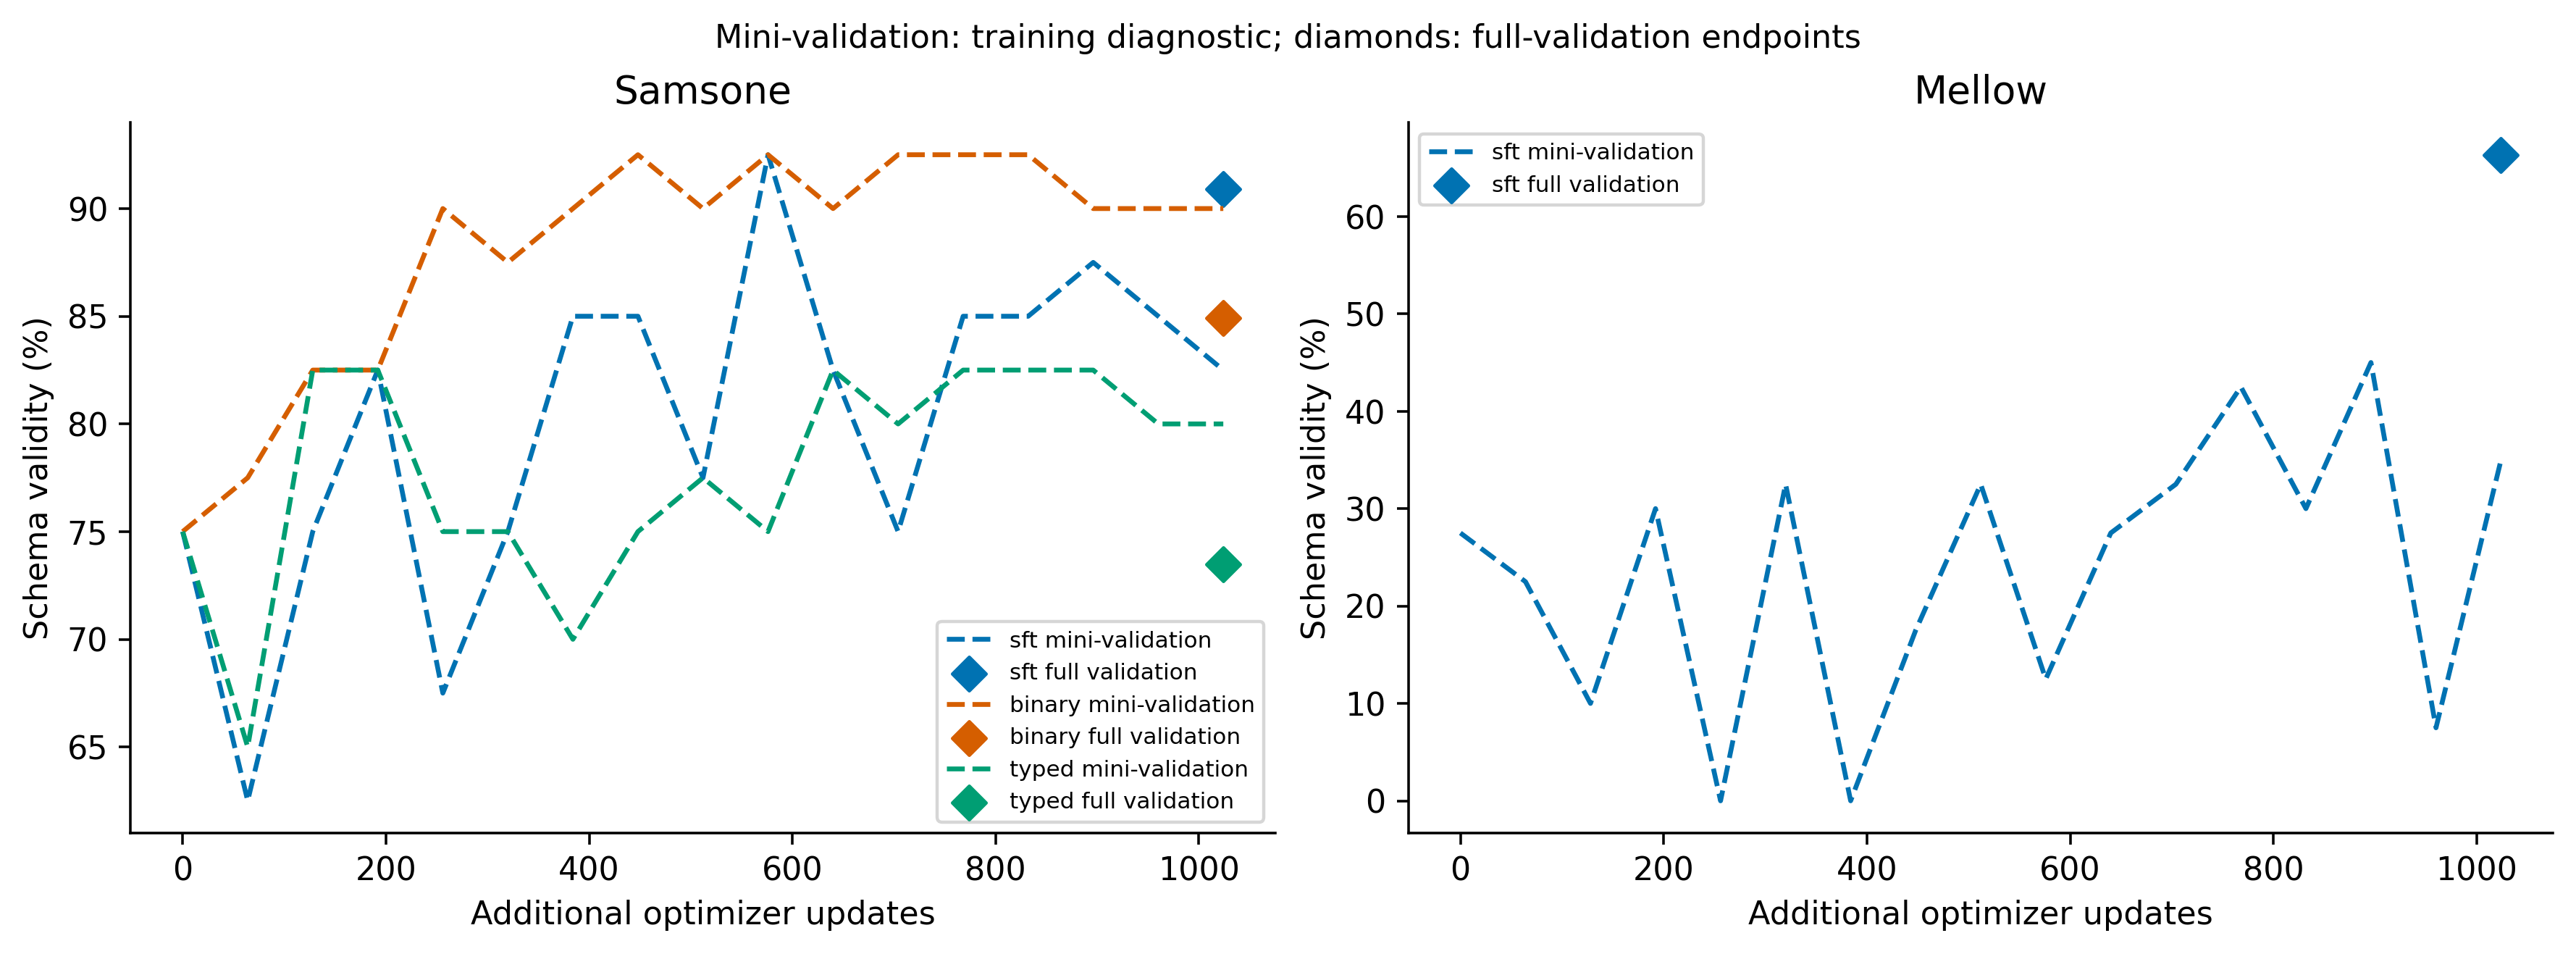

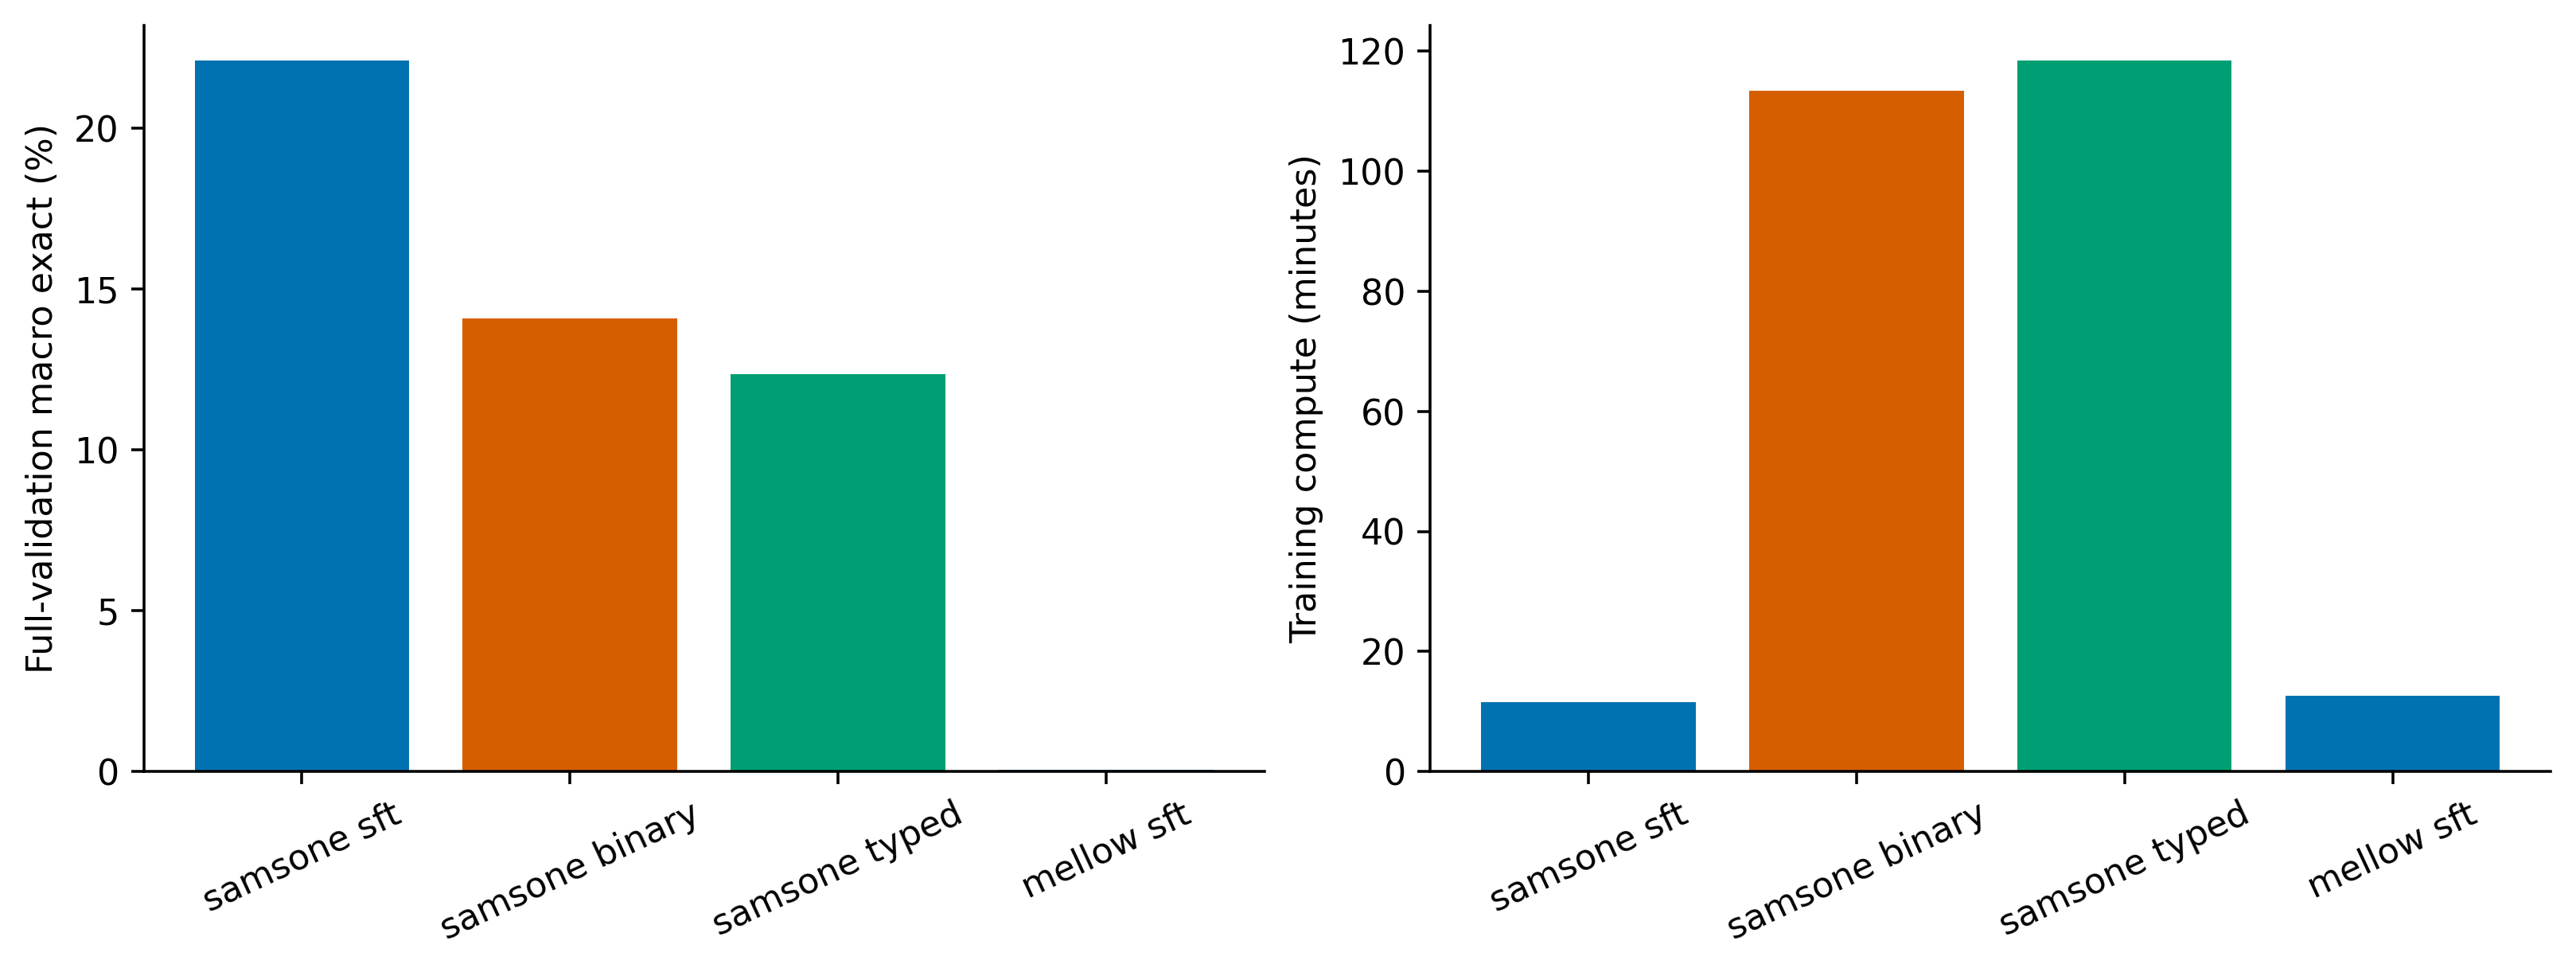

In [5]:
show_table('endpoints', ['model','arm','additional_updates','macro_exact','binary','argument_F1','schema_validity','training_minutes'])
figure('continuation1024')
figure('continuation1024_schema')
figure('continuation_endpoints')

## SFT-4096

The Samsone extension adds 3072 updates to +1024 SFT. It restores optimizer moments and scaler and resets the scheduler over the new segment. Full validation occurs every 512 additional updates; mini-validation every 64. Endpoint lineage is 4736. The mini panel remains a training diagnostic.

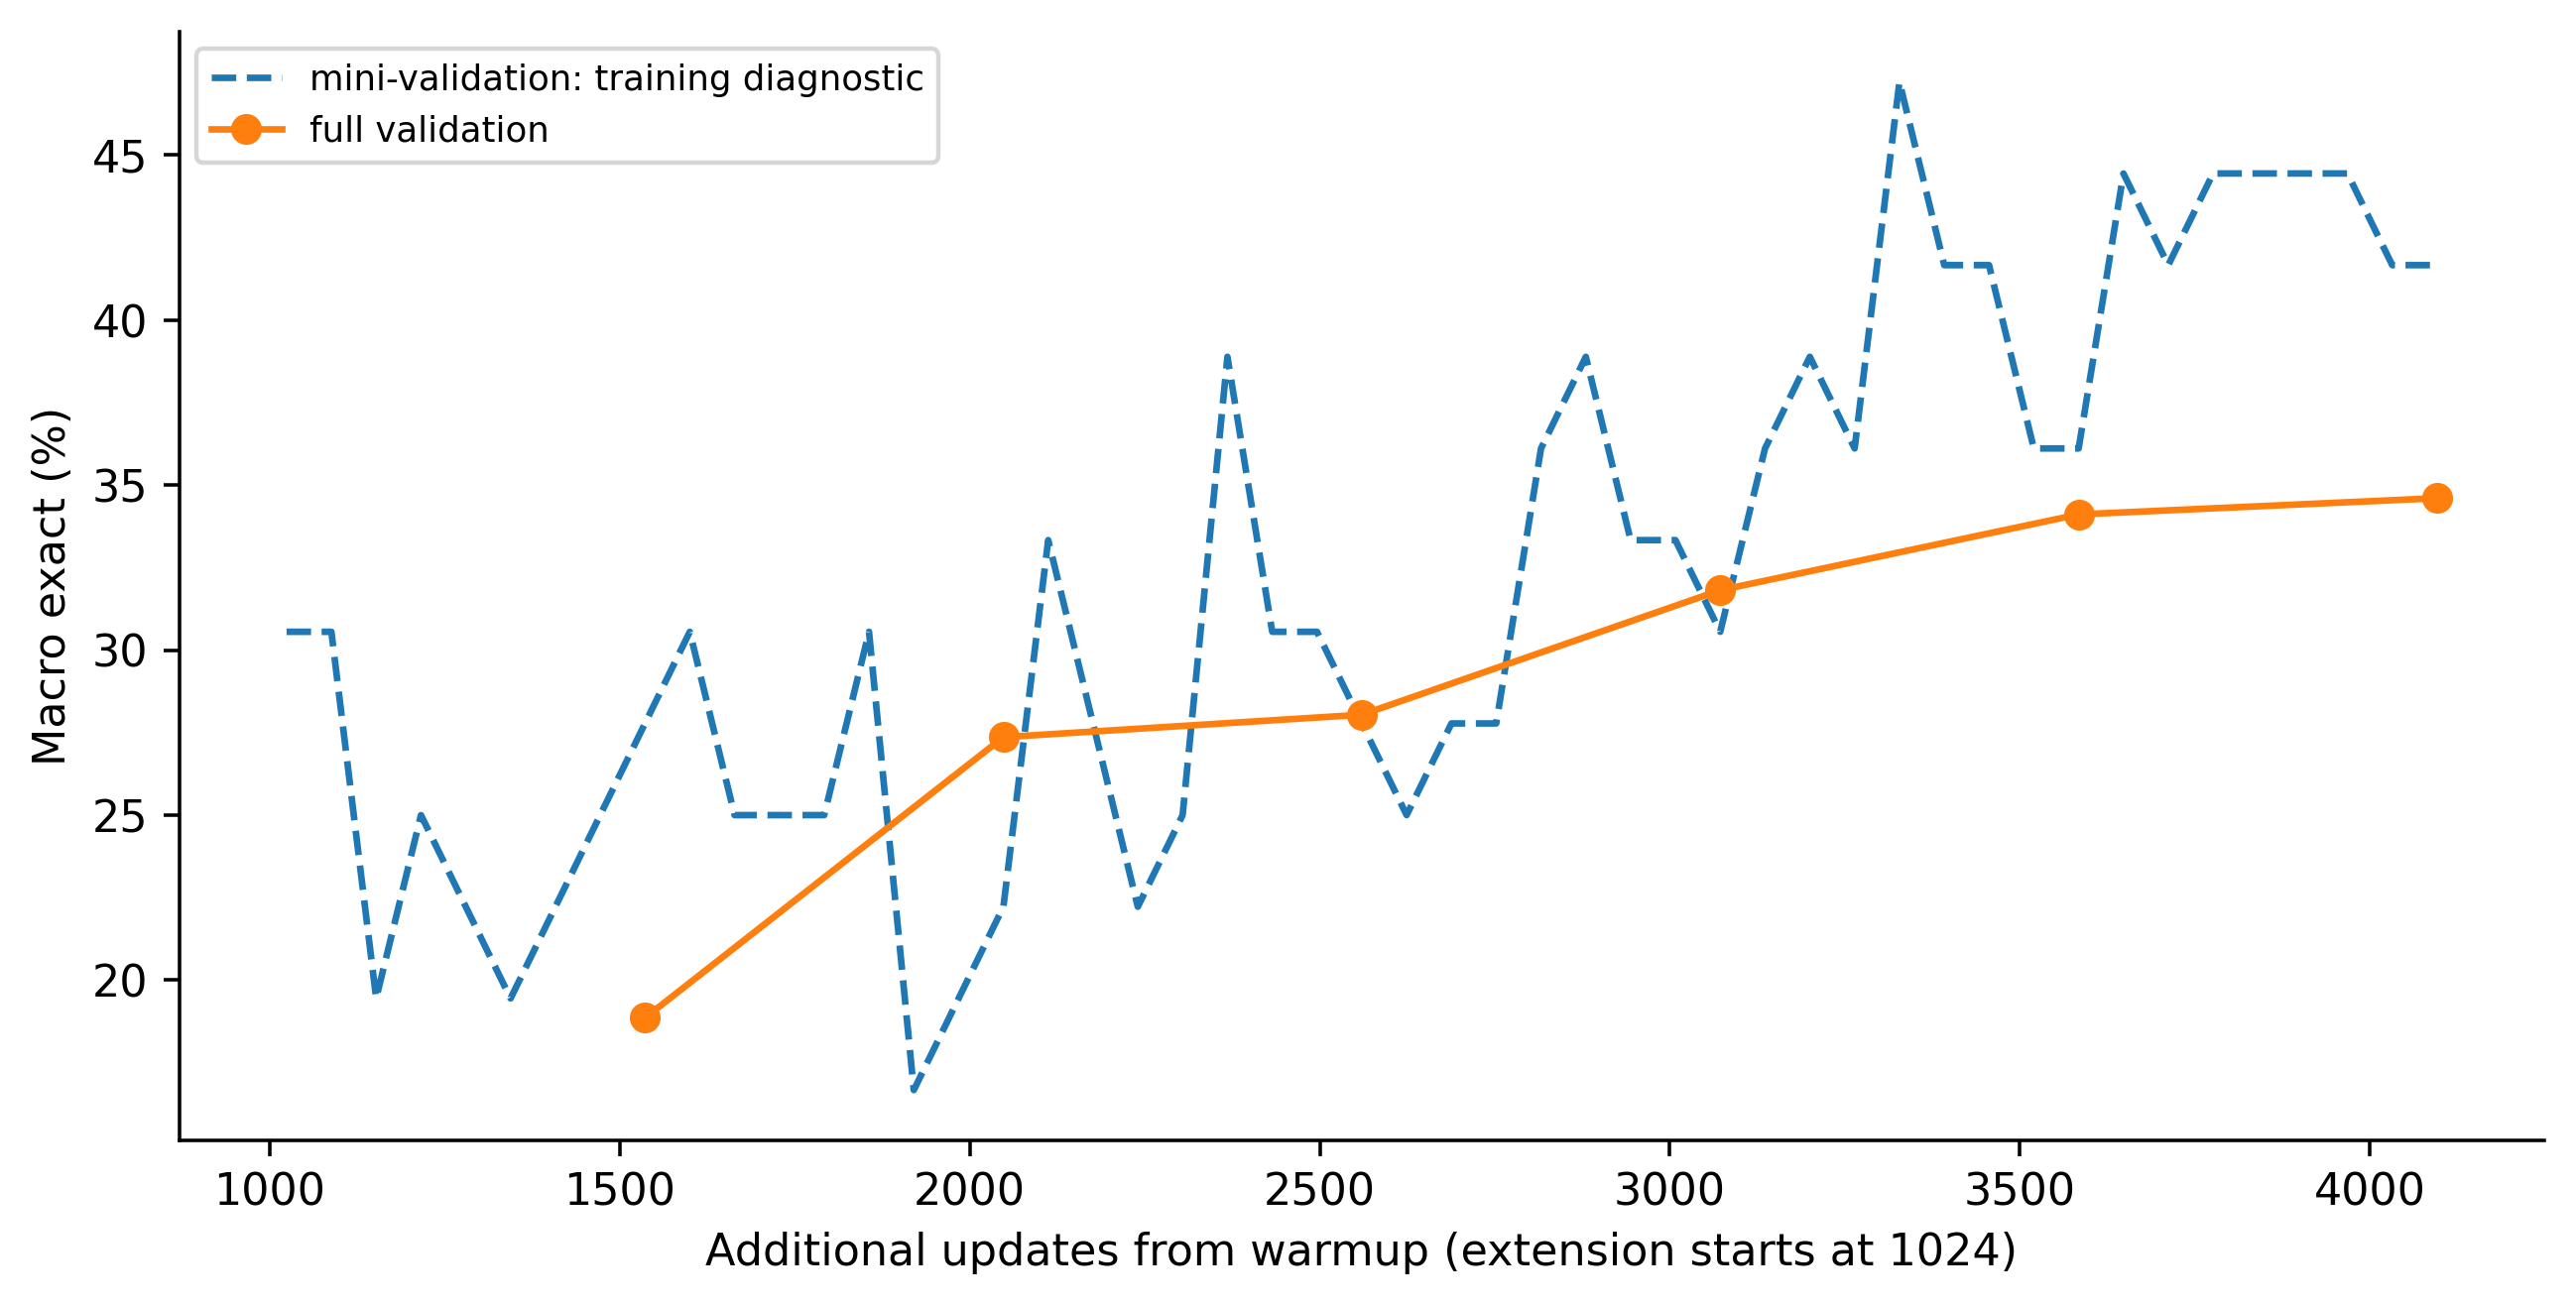

In [6]:
figure('sft4096')

## Appendix: +1024 training diagnostics

Left: response NLL for Samsone and Mellow SFT. Right: sampled KL estimator to the frozen reference for Samsone binary and typed GRPO. Curves use trailing 32-update means. Mellow has no +1024 GRPO run. KL is the recorded token-level estimator, without multiplication by the KL penalty coefficient; it is distinct from the GRPO objective.

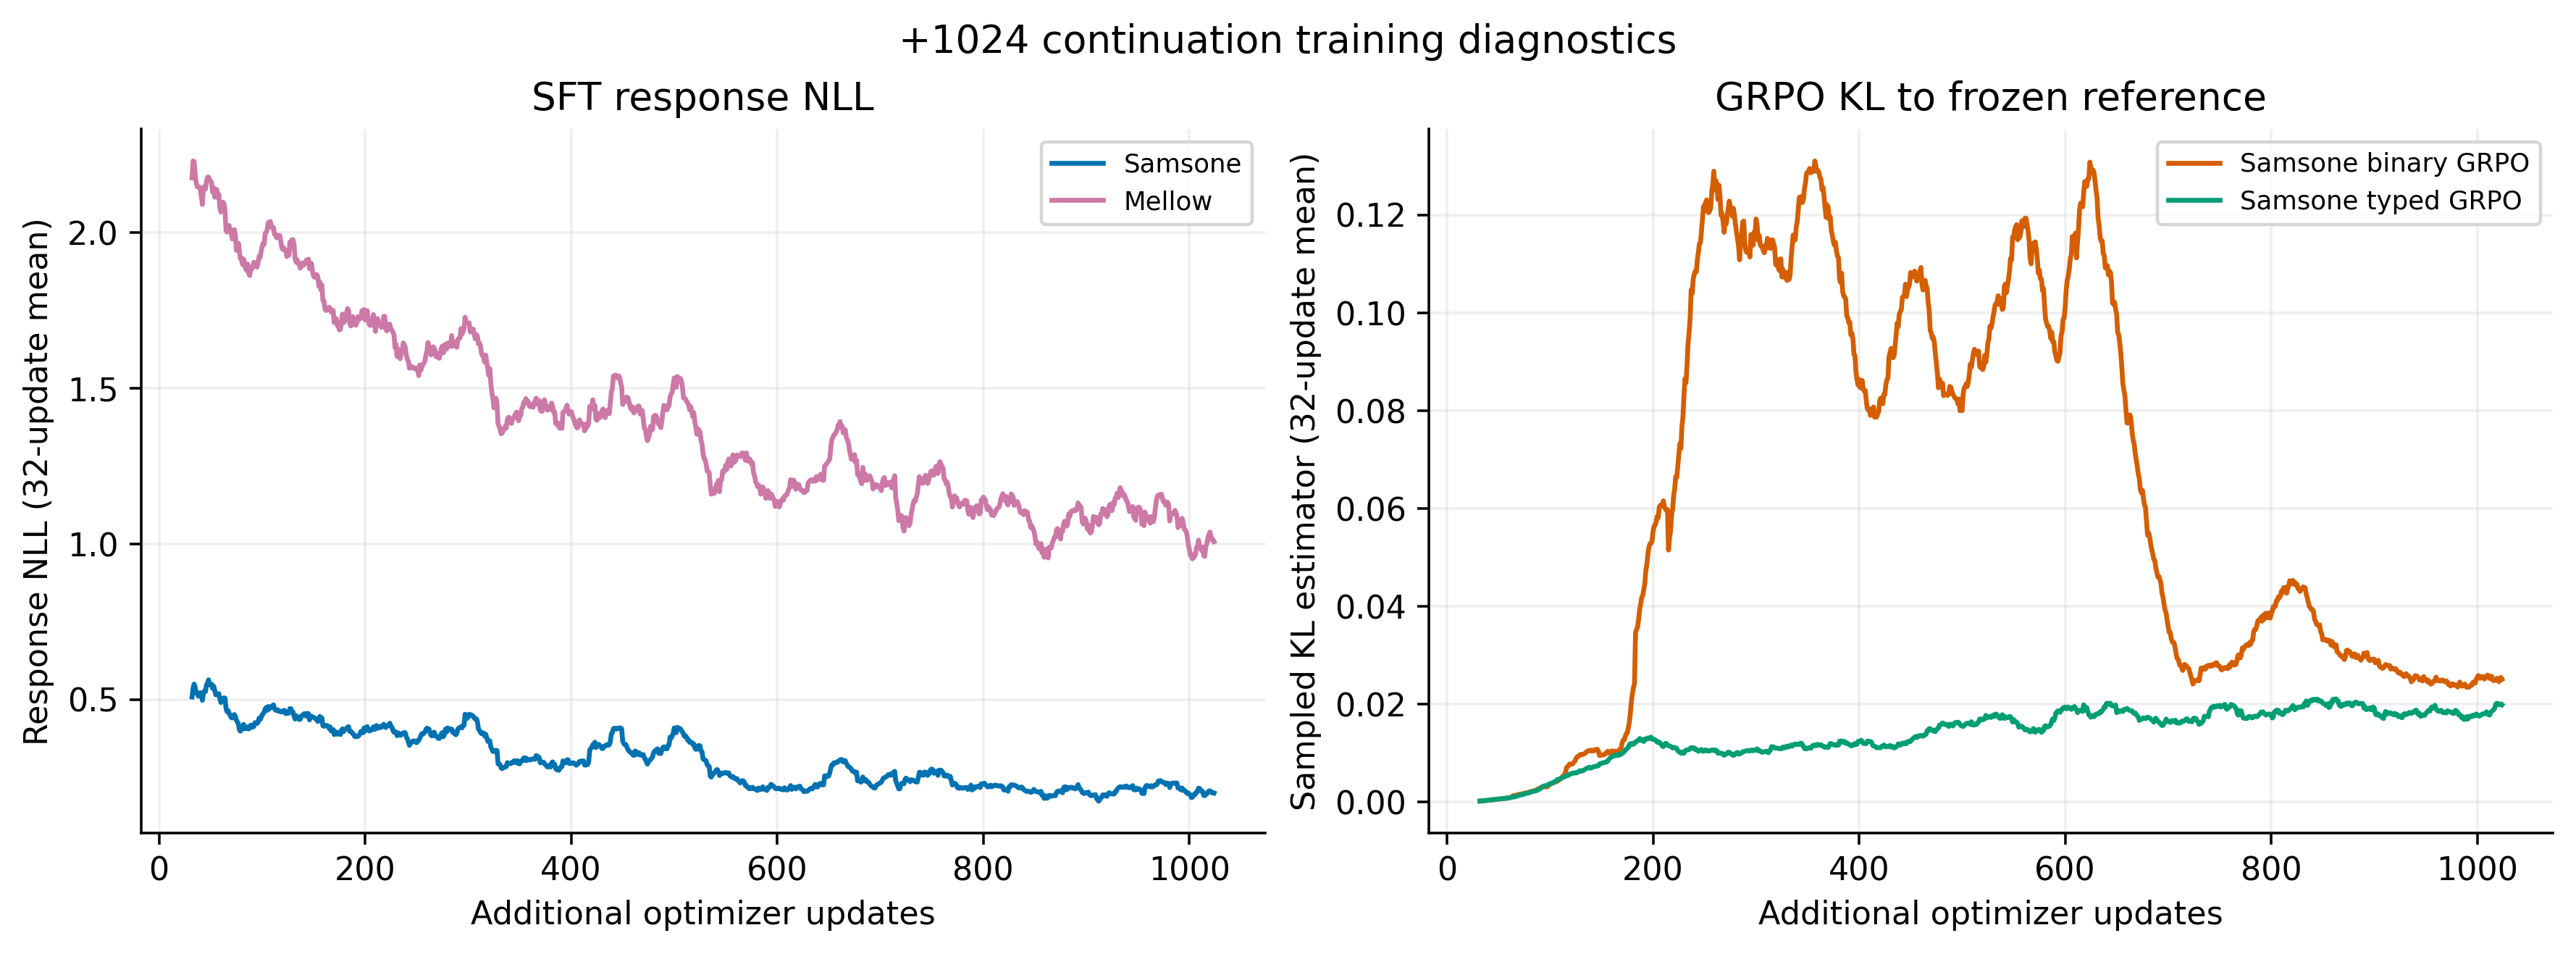

In [7]:
figure('continuation1024_training')

## Qualitative appendix

Post-hoc examples verified against saved prediction rows. IDs, gold references, raw outputs, source hashes and checkpoint provenance accompany the exports. These examples are not a representative sample.

In [8]:
display(Markdown((DEST / 'qualitative.md').read_text()))
show_table('provenance', ['run','parent_updates','lineage_updates','sampler_offset','precision','sha256'])

# Qualitative appendix

Post-hoc illustrative cases, not a representative accuracy sample. Transcripts are reader annotations; models received audio and catalogues.

## t1:row1375

Reference: `[{"name": "setdockstate", "arguments": {"deviceid": "vacuum_1"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"activatescene","arguments":{"sceneid":"\u004dovie_\u004eight"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"setlockstate","arguments":{"deviceid":"camera_1"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"activatescene","arguments":{"sceneid":"\u004dovie_\u004eight"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"setlockstate_home","arguments":{"deviceid":"vacuum_1"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"setdockstate","arguments":{"deviceid":"vacuum_1"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getdevicelist","arguments":{}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"thermostat_1","state":"\u0043losed"}}]}
```

## t2:row4273

Reference: `[{"name": "streamcamera", "arguments": {"deviceid": "nursery_cam"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"streamcamera","arguments":{"deviceid":"camera_1"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"getnetworkhealth","arguments":{"deviceid":"gateway_1"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"streamcamera","arguments":{"deviceid":"camera_1"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"streamcamera","arguments":{"deviceid":"camera_1"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"streamcamera","arguments":{"deviceid":"nursery_cam"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getnetworkhealth","arguments":{"deviceid":"gateway_1"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getnetworkhealth","arguments":{"deviceid":"gateway_1"}}]}
```

## t3:row3779

Reference: `[{"name": "stopworkout", "arguments": {}}, {"name": "findpairedphone", "arguments": {}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

sft1024; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"setalarm","arguments":{"time":"07:00","label":"\u0057ake \u0055p","repeat":null}}]}
```

## t4:row3503

Reference: `[{"name": "findpairedphone", "arguments": {}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0053leep"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0053tress"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0048eart_\u0052ate"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u004cast_\u004donth"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"findpairedphone","arguments":{}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u0054oday"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u0054oday"}}]}
```

## t5:row1267

Reference: `[{"name": "startcleaning", "arguments": {"deviceid": "vacuum_1", "zones": null}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"getappliancestatus","arguments":{"deviceid":"vacuum_1"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"getairquality","arguments":{"deviceid":"purifier_1"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"getappliancestatus","arguments":{"deviceid":"vacuum_1"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"getappliancestatus","arguments":{"deviceid":"hallway_1"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"startcleaning","arguments":{"deviceid":"vacuum_1","zones":null}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getappliancestate","arguments":{"deviceid":"vacuum_1"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getappliancestate","arguments":{"deviceid":"hallway_1"}}]}
```

## t6:row938

Reference: `[{"name": "setgaragedoor", "arguments": {"deviceid": "garage_1", "state": "Closed"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"getappliancestatus","arguments":{"deviceid":"garage"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"setgaragedoor","arguments":{"state":"\u004fpen","deviceid":"garage_1"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"getlockstate","arguments":{"deviceid":"garage"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"getlockstate","arguments":{"deviceid":"garage"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"setgaragedoor","arguments":{"deviceid":"garage_1","state":"\u0043losed"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getgevarient","arguments":{"deviceid":"garage_open"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getgevarient","arguments":{"deviceid":"garage_light"}}]}
```

## t7:row287

Reference: `[{"name": "getairquality", "arguments": {"deviceid": "sensor_1"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"getairquality_diag","arguments":{"deviceid":"sensor_1"}}]}
```

sft64; saved exact=1.0

```json
{"calls":[{"name":"getairquality","arguments":{"deviceid":"sensor_1"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"getairquality_diag","arguments":{"deviceid":"sensor_1"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"getairquality_diag","arguments":{"deviceid":"sensor_1"}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"getairquality","arguments":{"deviceid":"sensor_1"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getairquality_diag","arguments":{"deviceid":"sensor_1"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getairquality_diag","arguments":{"deviceid":"sensor_1"}}]}
```

## t8:row367

Reference: `[{"name": "getsleepsummary", "arguments": {"period": "Last_Night"}}, {"name": "findpairedphone", "arguments": {}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0053leep"}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0053leep"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"getbiometricdata","arguments":{"type":"\u0048eart_\u0052ate"}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u004cast_\u004donth"}}]}
```

sft1024; saved exact=0.0

```json
{"calls":[{"name":"getsleepsummary","arguments":{"period":"\u004cast_\u004eight"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u0054oday"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getactivitysummary","arguments":{"period":"\u0054oday"}}]}
```

## t1:row4171

Reference: `[{"name": "getlocation", "arguments": {}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"setcargostate","arguments":{}}]}
```

sft64; saved exact=0.0

```json
{"calls":[{"name":"setsteeringmode","arguments":{"mode":"\u0047en\u0044er"}}]}
```

binary64; saved exact=1.0

```json
{"calls":[{"name":"getlocation","arguments":{}}]}
```

typed64; saved exact=1.0

```json
{"calls":[{"name":"getlocation","arguments":{}}]}
```

sft1024; saved exact=1.0

```json
{"calls":[{"name":"getlocation","arguments":{}}]}
```

binary1024; saved exact=1.0

```json
{"calls":[{"name":"getlocation","arguments":{}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"getgearselection","arguments":{}}]}
```

## t1:row2781

Reference: `[{"name": "setsecuritymode", "arguments": {"mode": "Armed_Away"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"setdockstate","arguments":{"deviceid":"waffle_1","state":"\u0043losed"}}]}
```

sft64; saved exact=1.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0041way"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046","\u0046","level":null,"color":"#\u0047ood_\u0046","level":0}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046","\u0046","level":null,"color":"#\u0047ood_\u0046","level":null}}]}
```

sft1024; saved exact=0.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0048ome"}}]}
```

binary1024; saved exact=0.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046\u0046","\u0046","level":null}}]}
```

typed1024; saved exact=1.0

```json
{"calls":[{"name":"setsecuritymode","arguments":{"mode":"\u0041rmed_\u0041way"}}]}
```

## t1:row1533

Reference: `[{"name": "setpowerstate", "arguments": {"deviceid": "plug_1", "state": "Off"}}]`

parent; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fn"}}]}
```

sft64; saved exact=1.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fff"}}]}
```

binary64; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fn","level":null,"color":null}}]}
```

typed64; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fn","level":null,"color":null}}]}
```

sft1024; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fn"}}]}
```

binary1024; saved exact=1.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1"}}]}
```

typed1024; saved exact=0.0

```json
{"calls":[{"name":"setpowerstate","arguments":{"deviceid":"plug_1","state":"\u004fn"}}]}
```

## t1:row4045

Reference: `[{"name": "initiateautopark", "arguments": {}}]`

mellow_sft64_historical; saved exact=0.0

```json
{"calls":[{"name":"set"}}]}
```

Mellow historical +64 parent: 100%/256; lineage endpoint 320.
All checkpoint hashes and prediction source hashes are in evidence/qualitative.json and tables/provenance.csv.


run,parent_updates,lineage_updates,sampler_offset,precision,sha256
samsone-warmup-010,0,640,0,fp16,5601c21009911d68e21bdec7d918637206af98e243430dd362fdd510064855ac
samsone-warmup-030,0,640,0,fp16,bacbf9baa9b895fdd523107a534c8fa973de7b93b657fe3217308fc146ccf3a0
samsone-warmup-100,0,640,0,fp16,0c4c967326adaf8ee3e3e35683ab649c25865da68e55296296022b15e16ebb17
mellow-warmup-010,0,640,0,bf16,cfb2816d79ed92e968e3b36506a9933dc3ee5ae425f0dadfe23eceee853fd607
mellow-warmup-030,0,640,0,bf16,bd778bd9f92b6ab2f3504be3502e350d15e95293aca9153e4c178e0841102618
mellow-warmup-100,0,640,0,bf16,ea9d765392cb56a5925154a824ce4ae4d410b1cd001aa5afefe9e5f0aacac42d
samsone-continuation-sft,640,704,640,fp16,f15c944308bf15cc81003f382aef4c78648da2eb2a69b6986c6b8e655db31e0e
samsone-continuation-binary,640,704,640,fp16,73fb9da9de5014de951407b41a2c2ed6d79af76f677a4359e6121c528f48c8da
samsone-continuation-typed,640,704,640,fp16,2f42241cb7627800f096fdfcdf20d7c9628ffb590f93c3b9a12fe7af86a7412f
mellow-continuation-sft,256,320,640,bf16,60f1b4e15ab37543735b098da4abca5a922e64f2b6608a4c3395b35de55c5e10


## Caption drafts and audit

Vector PDF, 320-DPI PNG, CSV and LaTeX fragments are under `paper/generated`. Numerical tolerances and evidence paths are recorded in the audit. Regenerating figures does not reproduce stochastic training.

In [9]:
display(Markdown((DEST / 'captions.md').read_text()))
from nano_learning.audit import build_register
build_register()
display(Markdown((ROOT / 'docs/paper_discrepancies.md').read_text()))

# Caption drafts

All results use seed 17 and the filtered Audio2Tool benchmark. Full-validation endpoints describe this benchmark, not deployment performance. CSV metrics are fractions; figure axes convert them to percentages.

- **Warmups (2×3):** rows Samsone/Mellow; columns response NLL (trailing 32-update mean), full-validation macro exact, and full-validation schema validity. All curves show 10/30/100% pools. Mellow ties at zero macro exact; 10% is selected by the smallest-pool tie-break, not a unique accuracy maximum. Full validation (2,141 entries / 1,105 requests), macro exact at updates 256, 512 and 640, independent released-weight parents, 10/30/100% component pools. Selection compares only update 640, ties favor the smallest pool. Both models select 10%/640.
- **SFT loss:** response NLL, trailing 32-update mean, separated from GRPO objectives. Local updates reset per stage; the SFT extension is displayed at continuation updates 1024–4096.
- **GRPO loss:** clipped group-relative objective including KL, trailing 32-update mean. Its scale is not comparable to SFT NLL. Pilot and +1024 runs use their respective recorded parents and schedules.
- **Pilot +64:** held-out pilot test (2,126 entries / 1,096 requests). Samsone parent 10%/640, endpoint lineage 704. Mellow historical parent 100%/256, endpoint lineage 320. These values do not measure corrected-parent Mellow +64.
- **+1024 trajectories:** mini-validation: training diagnostic. 40 recording entries, 40 distinct requests, 36 source components. Every 64 updates; diamonds mark the full-validation endpoint. Independent branches from each model's 10%/640 warmup, endpoint lineage 1664. Mellow has SFT only.
- **+1024 endpoints:** full-validation macro exact and sum of saved optimizer-step elapsed seconds / 60. Timing excludes model loading, validation and checkpoint I/O; it is not end-to-end wall time. No full-split intermediate measurements are inferred from the mini panel.
- **SFT-4096:** Samsone extension inherits +1024 SFT weights, optimizer moments and scaler, with a new 3072-update scheduler. Mini-validation every 64 local updates; full validation every 512 local updates and endpoint. Lineage 4736. Endpoint training minutes sum both SFT segments.
- **Qualitative appendix:** verified saved raw predictions with IDs, references and provenance; post-hoc selection does not estimate prevalence.


# Important remaining paper discrepancies

Review of the latest author-updated draft. Placeholder figures are excluded. The manuscript was not edited.

## mellow-lineage (PAPER.tex:558)

The latest table still labels the historical Mellow parent 640 and +64 endpoints 704; saved runs used parent 256 and endpoints 320.

**Suggested correction:** Change the four Mellow lineage cells to 256/320/320/320 and identify its 100% warmup pool in the caption. No rerun is needed.

## discussion (PAPER.tex:598)

Discussion still names an unadapted base SmolLM2 evaluation and assigns the long-run comparison to test. The measurements are released audio-model pilot test results and Samsone +1024 full-validation results. 22.09 minus 14.07 is 8.01 percentage points, not nine.

**Suggested correction:** Name the released Samsone/Mellow checkpoints; report 22.09% versus 14.07% full-validation macro exact, a gap of 8.01 points.

## selection-narrative (PAPER.tex:508)

The selection paragraph still combines all-checkpoint ranking with smallest-pool ties. Historical Mellow selection used 100%/256, while corrected selection compares 640 endpoints only.

**Suggested correction:** Distinguish the historical pilot parent from retrospective endpoint-only selection; do not call the corrected rule the original executed rule.

## hardware (PAPER.tex:485)

Training hardware is now accurately described, but the new claim that evaluation used V100/FP16 has no supporting evaluation-device record in the saved study evidence.

**Suggested correction:** Remove the V100 evaluation assertion unless a separate evaluation log establishes the device and precision; Mellow training uses BF16.

## grpo-normalization (PAPER.tex:354)

The advantage formula still omits the stabilizer and is undefined for equal-reward groups. Code uses population standard deviation plus 1e-6.

**Suggested correction:** Add +10^-6 to the denominator and specify population standard deviation.

## scope-limits (PAPER.tex:604)

The unqualified statement that Mellow did not continue with RL obscures its completed historical +64 GRPO branches.

**Suggested correction:** Specify that no Mellow +1024 GRPO continuation was run; the +64 arms remain reported separately.

## conclusion (PAPER.tex:608)

Universal zero-shot incapacity and causal architecture/initialization conclusions exceed this two-model, single-seed comparison.

**Suggested correction:** Restrict zero-shot findings to the tested released audio checkpoints and describe architecture/initialization as possible explanations rather than isolated causes.

These corrections require no new training. Evaluation hardware should be substantiated from its actual execution records.
